# 03 — Benchmark LLM trên EKS và so sánh A/B

Qwen2.5-1.5B (llama.cpp, CPU) trên EKS `platform-apps`. Ba nguồn, tất cả đọc từ file đã commit:
1. [`bench-llm-eks-t*-20261030.json`](../docs/evidence/aws/): `bench_llm.py`, thử số luồng llama.cpp (3, 4, 6) ở các mức đồng thời 1/2/4;
2. [`llmd-benchmark/`](../docs/evidence/aws/llmd-benchmark/): llm-d-benchmark (inference-perf), ba mức tải 0,1/0,2/0,4 request/giây;
3. A/B: Prometheus và kết quả eval của hai Agent (1,5B và 0,5B).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Số luồng llama.cpp và độ đồng thời

Mỗi mức chỉ 8 request, nên chênh dưới ~10% coi như hòa.

In [2]:
bench = pd.concat(
    [
        pd.read_json(p, lines=True)
        for p in sorted((EVIDENCE / "aws").glob("bench-llm-eks-t*-20261030.json"))
    ]
)
bench["luồng"] = bench["label"].str.removeprefix("eks-t")
bench[["luồng", "concurrency", "requests", "p50_s", "p95_s", "req_per_s", "output_tok_per_s"]]

,luồng,concurrency,requests,p50_s,p95_s,req_per_s,output_tok_per_s
0,3,1,8,5.38,5.62,0.204,10.7
1,3,2,8,7.70,14.97,0.214,11.3
2,3,4,8,10.96,12.44,0.345,17.8
0,4,1,8,4.74,5.19,0.229,12.0
1,4,2,8,7.60,13.93,0.225,11.8
2,4,4,8,12.57,19.14,0.269,14.0
0,6,1,8,5.66,6.25,0.188,9.9
1,6,2,8,8.63,14.70,0.204,10.6
2,6,4,8,11.02,12.60,0.342,17.7


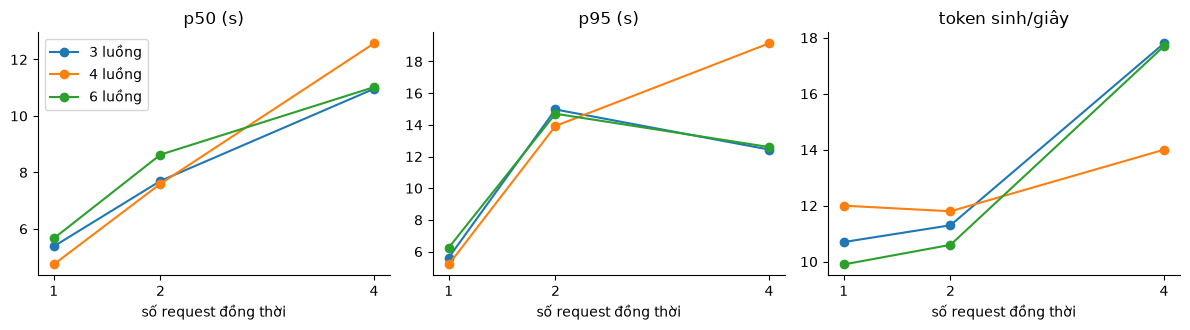

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for (title, col), ax in zip(
    {"p50 (s)": "p50_s", "p95 (s)": "p95_s", "token sinh/giây": "output_tok_per_s"}.items(), axes
):
    for threads, g in bench.groupby("luồng"):
        ax.plot(g["concurrency"], g[col], marker="o", label=f"{threads} luồng")
    ax.set_xticks([1, 2, 4])
    ax.set_xlabel("số request đồng thời")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.show()

In [4]:
t = bench.pivot(index="concurrency", columns="luồng", values="output_tok_per_s")
p50 = bench.pivot(index="concurrency", columns="luồng", values="p50_s")
print("token sinh/giây theo (đồng thời, số luồng):")
print(t.to_string())
print(
    f"\n3 luồng: đồng thời 1 -> 4 tăng thông lượng {t.loc[4, '3'] / t.loc[1, '3']:.2f}x, p50 tăng {p50.loc[4, '3'] / p50.loc[1, '3']:.2f}x"
)

token sinh/giây theo (đồng thời, số luồng):
luồng           3     4     6
concurrency                  
1            10.7  12.0   9.9
2            11.3  11.8  10.6
4            17.8  14.0  17.7

3 luồng: đồng thời 1 -> 4 tăng thông lượng 1.66x, p50 tăng 2.04x


Thêm request đồng thời tăng thông lượng token (khoảng 1,7 lần khi từ 1 lên 4) nhưng **p50 tăng gần gấp đôi**: CPU là nút cổ chai, phần tăng thêm chủ yếu là xếp hàng.
Ở mức đồng thời 4, cấu hình 4 luồng kém rõ nhất (14,0 token/giây so với 17,7–17,8 của 3 và 6 luồng); 3 và 6 luồng gần như bằng nhau, nên chọn 3 luồng vì tốn ít CPU hơn.
Mỗi ô chỉ 8 request, nên chỉ coi là xu hướng.

## 2. llm-d-benchmark (inference-perf), 3 mức tải

In [5]:
import re

rates = [
    float(x)
    for x in re.findall(
        r"rate:\s*([\d.]+)",
        (EVIDENCE / "aws" / "llmd-benchmark" / "llmd-inference-perf-qwen-cpu.yaml").read_text(),
    )
]
rows = []
for i, rate in enumerate(rates):
    d = json.loads(
        (EVIDENCE / "aws" / "llmd-benchmark" / f"stage_{i}_lifecycle_metrics.json").read_text()
    )
    s = d["successes"]
    rows.append(
        {
            "tải (req/s)": rate,
            "request": s["count"],
            "lỗi": (d["failures"] or {}).get("count", 0),
            "TTFT trung vị (s)": s["latency"]["time_to_first_token"]["median"],
            "TTFT p90 (s)": s["latency"]["time_to_first_token"]["p90"],
            "độ trễ trung vị (s)": s["latency"]["request_latency"]["median"],
            "độ trễ p90 (s)": s["latency"]["request_latency"]["p90"],
            "đạt (req/s)": s["throughput"]["requests_per_sec"],
            "token sinh/s": s["throughput"]["output_tokens_per_sec"],
        }
    )
llmd = pd.DataFrame(rows)
llmd.round(3)

,tải (req/s),request,lỗi,TTFT trung vị (s),TTFT p90 (s),độ trễ trung vị (s),độ trễ p90 (s),đạt (req/s),token sinh/s
0,0.1,6,0,1.881,2.864,5.485,6.304,0.092,2.950
1,0.2,12,0,1.955,4.227,7.220,9.970,0.232,7.078
2,0.4,24,0,5.616,14.996,13.643,20.646,0.340,10.237


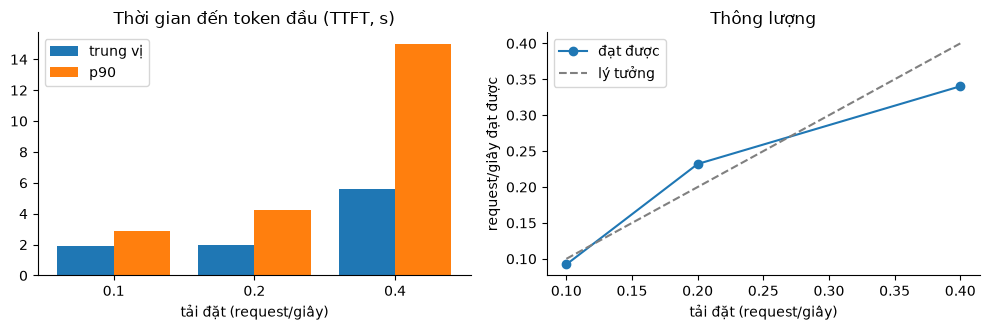

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(llmd))
axes[0].bar(x - 0.2, llmd["TTFT trung vị (s)"], 0.4, label="trung vị")
axes[0].bar(x + 0.2, llmd["TTFT p90 (s)"], 0.4, label="p90")
axes[0].set_xticks(x, llmd["tải (req/s)"])
axes[0].set_xlabel("tải đặt (request/giây)")
axes[0].set_title("Thời gian đến token đầu (TTFT, s)")
axes[0].legend()
axes[1].plot(llmd["tải (req/s)"], llmd["đạt (req/s)"], marker="o", label="đạt được")
axes[1].plot(llmd["tải (req/s)"], llmd["tải (req/s)"], ls="--", color="gray", label="lý tưởng")
axes[1].set_xlabel("tải đặt (request/giây)")
axes[1].set_ylabel("request/giây đạt được")
axes[1].set_title("Thông lượng")
axes[1].legend()
plt.tight_layout()
plt.show()

In [7]:
assert llmd["lỗi"].sum() == 0 and llmd["request"].sum() == 42
print("tổng", int(llmd["request"].sum()), "request,", int(llmd["lỗi"].sum()), "lỗi")

tổng 42 request, 0 lỗi


Mức 0,1 và 0,2 req/s được phục vụ ổn (TTFT trung vị ~1,9 s). Ở **0,4 req/s hệ bão hòa**: TTFT trung vị tăng gần ba lần (5,6 s), p90 gần 15 s,
và thông lượng đạt được (0,34) thấp hơn tải đặt (0,4). Đây là một lần chạy ngắn (60 s mỗi mức, prompt ~128 token), chưa có khoảng tin cậy.

## 3. A/B: hai model, hai Agent

In [8]:
ab = json.loads((EVIDENCE / "aws" / "ab-llm-prometheus-20261031.json").read_text())
print(ab["setup"][:230], "...")
pd.DataFrame({"tăng trong 1 giờ": ab["increase_1h"], "tổng": ab["total"]})

agentgateway virtual model platform-chat, weighted 1:1 between qwen2.5-1.5b-instruct (A, deploy qwen) and qwen2.5-0.5b-instruct (B, deploy qwen-small) on EKS platform-apps; traffic from scripts/evidence/bench_llm.py --model platfo ...


,tăng trong 1 giờ,tổng
qwen2.5-1.5b-instruct,54.23,642
qwen2.5-0.5b-instruct,27.58,30


In [9]:
print(ab["note"])

B only exists since today (total 30 = all bench traffic it received); A also serves data-agent, coordinator and sandbox agents, so its count is higher than the bench share alone


In [10]:
evals = pd.concat(
    [
        pd.read_json(p, lines=True)
        for p in sorted((EVIDENCE / "aws").glob("agent-eval-data-agent*-20261031.jsonl"))
    ]
)
graded = evals[(evals["gradable"]) & (evals["agent"].isin(["data-agent", "data-agent-b"]))]
summary = (
    graded.groupby("agent")
    .agg(câu=("pass", "size"), đạt=("pass", "sum"), giây_trung_bình=("seconds", "mean"))
    .round(2)
)
summary["tỷ lệ đạt"] = (summary["đạt"] / summary["câu"]).round(3)
summary

,câu,đạt,giây_trung_bình,tỷ lệ đạt
agent,,,,
data-agent,12,12,10.17,1.000
data-agent-b,12,4,6.00,0.333


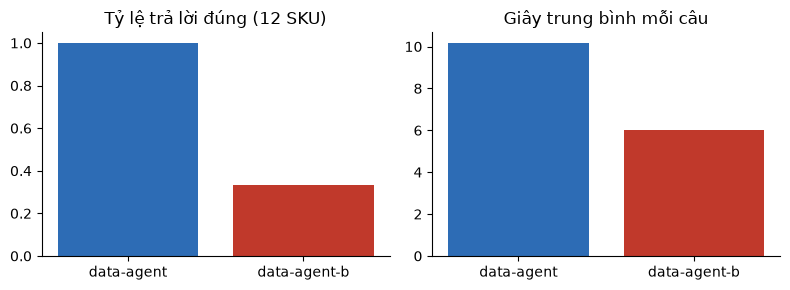

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(summary.index, summary["tỷ lệ đạt"], color=["#2d6cb5", "#c0392b"])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Tỷ lệ trả lời đúng (12 SKU)")
axes[1].bar(summary.index, summary["giây_trung_bình"], color=["#2d6cb5", "#c0392b"])
axes[1].set_title("Giây trung bình mỗi câu")
plt.tight_layout()
plt.show()

**Đánh đổi rõ ràng:** model 0,5B nhanh hơn (khoảng 6,0 s so với 10,2 s mỗi câu, tức ngắn hơn ~40%) nhưng trả lời đúng ít hơn nhiều so với 1,5B trên cùng 12 SKU (4/12 so với 12/12).
Số mẫu nhỏ (12) nên chỉ dùng để thấy xu hướng, không dùng để ước lượng tỷ lệ chính xác.